# Evaluasi & Perbandingan Kinerja Metode: Multinomial Naive Bayes vs K-Nearest Neighbor (KNN)

Notebook ini mengimplementasikan **Subbab 3.12.6 (Perbandingan Hasil Evaluasi)**, **Subbab 3.13 (Perbandingan Kinerja Metode)**, serta menyajikan bahan pembahasan lengkap untuk **Bab IV (Hasil dan Pembahasan)** dan **Bab V (Kesimpulan)** skripsi Anda.

### Alur Proses pada Notebook Ini:
1. **Memuat Hasil Evaluasi Multinomial Naive Bayes & KNN** dari folder penyimpanan.
2. **Rekapitulasi Pemilihan Nilai $K$ Terbaik pada KNN ($K = 3, 5, 7, 9, 11$)**.
3. **Tabel Perbandingan Kinerja Utama**: Multinomial Naive Bayes vs KNN ($K$ Terbaik) beserta selisih keunggulannya.
4. **Visualisasi Grafik Batang (*Bar Chart*) Perbandingan Metrik Evaluasi** (*Accuracy*, *Precision*, *Recall*, dan *F1-Score*).
5. **Perbandingan *Side-by-Side Confusion Matrix* & Bedah Pola Kesalahan Klasifikasi** (contoh kasus di mana MNB benar tapi KNN salah, dan sebaliknya).
6. **Pengujian Hipotesis Penelitian ($H_0$ vs $H_1$) & Kesimpulan Akhir Metode Terbaik**.

---
## 1. Import Library & Memuat Paket Hasil Evaluasi Kedua Metode

In [1]:
import os
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from scipy.stats import chi2

# Buat folder khusus untuk menyimpan tabel dan gambar grafik hasil perbandingan (siap masuk Word Skripsi)
folder_perbandingan = "../data/hasil-perbandingan"
os.makedirs(folder_perbandingan, exist_ok=True)

# 1. Memuat hasil evaluasi Multinomial Naive Bayes
eval_mnb = joblib.load("../data/model-naive-bayes/evaluasi_naive_bayes.pkl")

# 2. Memuat hasil evaluasi K-Nearest Neighbor (KNN)
eval_knn = joblib.load("../data/model-knn/evaluasi_knn.pkl")

# 3. Memuat data uji untuk analisis kasus prediksi
paket_data = joblib.load("../data/tfidf_split_data.pkl")
X_test_text = paket_data['X_test_text']
y_test = paket_data['y_test']

k_terbaik = eval_knn['k_terbaik']
print("=== BERHASIL MEMUAT HASIL EVALUASI KEDUA METODE ===")
print(f"1. Metode Pertama : {eval_mnb['nama_metode']} (alpha = 1.0)")
print(f"2. Metode Kedua   : {eval_knn['nama_metode']} (Cosine Similarity)")
print(f"3. Jumlah Data Uji: {len(y_test)} ulasan")

=== BERHASIL MEMUAT HASIL EVALUASI KEDUA METODE ===
1. Metode Pertama : Multinomial Naive Bayes (alpha = 1.0)
2. Metode Kedua   : K-Nearest Neighbor (K=11) (Cosine Similarity)
3. Jumlah Data Uji: 2147 ulasan


---
## 2. Ringkasan Pemilihan Nilai $K$ Terbaik pada Metode KNN

**Sesuai Subbab 3.13 Proposal Skripsi:**
Sebelum membandingkan KNN dengan Multinomial Naive Bayes, terlebih dahulu ditentukan konfigurasi nilai $K$ terbaik dari pengujian $K = 3, 5, 7, 9, \text{dan } 11$.

In [2]:
df_variasi_k = eval_knn['tabel_variasi_k'].copy()
df_variasi_k['Status'] = np.where(df_variasi_k['Nilai K'] == k_terbaik, '⭐ K Terbaik', '-')

kolom_k = ['Nilai K', 'Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'TP', 'TN', 'FP', 'FN', 'Status']
print(f"Tabel Rekapitulasi Pengujian Variasi Nilai K pada KNN (K Terbaik = {k_terbaik}):")
df_variasi_k[kolom_k]

Tabel Rekapitulasi Pengujian Variasi Nilai K pada KNN (K Terbaik = 11):


,Nilai K,Accuracy (%),Precision (%),Recall (%),F1-Score (%),TP,TN,FP,FN,Status
0,3,84.54,81.94,90.51,86.02,1021,794,225,107,-
1,5,85.42,83.05,90.78,86.74,1024,810,209,104,-
2,7,85.84,83.44,91.13,87.12,1028,815,204,100,-
3,9,86.45,84.28,91.22,87.61,1029,827,192,99,-
4,11,87.28,85.65,91.05,88.27,1027,847,172,101,⭐ K Terbaik


---
## 3. Tabel Perbandingan Kinerja Metode: Multinomial Naive Bayes vs KNN ($K$ Terbaik)

**Sesuai Subbab 3.12.6 & 3.13 Proposal Skripsi:**
Setelah nilai $K$ terbaik diperoleh ($K = 11$), hasil K-Nearest Neighbor tersebut dibandingkan secara langsung dengan hasil **Multinomial Naive Bayes** berdasarkan nilai **Accuracy, Precision, Recall, F1-Score**, serta rincian **Confusion Matrix (TP, TN, FP, FN)**.

### Catatan Belajar untuk Cara Membaca Tabel Perbandingan:
- **Accuracy:** Mengukur persentase tebakan benar secara keseluruhan (baik positif maupun negatif).
- **Precision:** Mengukur seberapa tepat model ketika menebak suatu ulasan sebagai Positif (semakin sedikit *False Positive [FP]*, maka *Precision* semakin tinggi).
- **Recall:** Mengukur seberapa banyak ulasan Positif asli yang berhasil ditemukan oleh model (semakin sedikit *False Negative [FN]*, maka *Recall* semakin tinggi).
- **F1-Score:** Ukuran keseimbangan rata-rata harmonik antara *Precision* dan *Recall* (menjadi acuan utama bersama *Accuracy*).

In [3]:
# 1. Menyusun Tabel Perbandingan Head-to-Head: Multinomial Naive Bayes vs KNN (K Terbaik)
acc_mnb_pct = round(eval_mnb['accuracy'] * 100, 2)
prec_mnb_pct = round(eval_mnb['precision'] * 100, 2)
rec_mnb_pct = round(eval_mnb['recall'] * 100, 2)
f1_mnb_pct = round(eval_mnb['f1_score'] * 100, 2)

acc_knn_pct = round(eval_knn['accuracy'] * 100, 2)
prec_knn_pct = round(eval_knn['precision'] * 100, 2)
rec_knn_pct = round(eval_knn['recall'] * 100, 2)
f1_knn_pct = round(eval_knn['f1_score'] * 100, 2)

df_perbandingan_utama = pd.DataFrame({
    'Metode Klasifikasi': [
        'Multinomial Naive Bayes (alpha=1.0)',
        f'K-Nearest Neighbor (K={k_terbaik}, Cosine)',
        'Selisih (MNB - KNN)'
    ],
    'Accuracy (%)': [
        acc_mnb_pct,
        acc_knn_pct,
        f"{acc_mnb_pct - acc_knn_pct:+.2f}%"
    ],
    'Precision (%)': [
        prec_mnb_pct,
        prec_knn_pct,
        f"{prec_mnb_pct - prec_knn_pct:+.2f}%"
    ],
    'Recall (%)': [
        rec_mnb_pct,
        rec_knn_pct,
        f"{rec_mnb_pct - rec_knn_pct:+.2f}%"
    ],
    'F1-Score (%)': [
        f1_mnb_pct,
        f1_knn_pct,
        f"{f1_mnb_pct - f1_knn_pct:+.2f}%"
    ],
    'TP': [eval_mnb['TP'], eval_knn['TP'], eval_mnb['TP'] - eval_knn['TP']],
    'TN': [eval_mnb['TN'], eval_knn['TN'], eval_mnb['TN'] - eval_knn['TN']],
    'FP': [eval_mnb['FP'], eval_knn['FP'], eval_mnb['FP'] - eval_knn['FP']],
    'FN': [eval_mnb['FN'], eval_knn['FN'], eval_mnb['FN'] - eval_knn['FN']]
})

# Simpan ke CSV untuk tabel Bab IV Skripsi
df_perbandingan_utama.to_csv(f"{folder_perbandingan}/tabel_perbandingan_utama_mnb_vs_knn.csv", index=False)

print("=== TABEL PERBANDINGAN UTAMA: MULTINOMIAL NAIVE BAYES VS KNN (K TERBAIK) ===")
display(df_perbandingan_utama)

# 2. Menyusun Tabel Perbandingan Lengkap (MNB beserta Seluruh Variasi K pada KNN)
baris_mnb_lengkap = pd.DataFrame([{
    'Metode': 'Multinomial Naive Bayes (alpha=1.0)',
    'Accuracy (%)': acc_mnb_pct,
    'Precision (%)': prec_mnb_pct,
    'Recall (%)': rec_mnb_pct,
    'F1-Score (%)': f1_mnb_pct,
    'TP': eval_mnb['TP'],
    'TN': eval_mnb['TN'],
    'FP': eval_mnb['FP'],
    'FN': eval_mnb['FN']
}])

kolom_gabung = ['Metode', 'Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'TP', 'TN', 'FP', 'FN']
df_semua_model = pd.concat([baris_mnb_lengkap, df_variasi_k[kolom_gabung]], ignore_index=True)
df_semua_model.to_csv(f"{folder_perbandingan}/tabel_perbandingan_semua_konfigurasi.csv", index=False)

print("\n=== TABEL REKAPITULASI SELURUH EKSPERIMEN (MNB & KNN K=3, 5, 7, 9, 11) ===")
display(df_semua_model)

=== TABEL PERBANDINGAN UTAMA: MULTINOMIAL NAIVE BAYES VS KNN (K TERBAIK) ===


,Metode Klasifikasi,Accuracy (%),Precision (%),Recall (%),F1-Score (%),TP,TN,FP,FN
0,Multinomial Naive Bayes (alpha=1.0),89.75,96.42,83.6,89.55,943,984,35,185
1,"K-Nearest Neighbor (K=11, Cosine)",87.28,85.65,91.05,88.27,1027,847,172,101
2,Selisih (MNB - KNN),+2.47%,+10.77%,-7.45%,+1.28%,-84,137,-137,84



=== TABEL REKAPITULASI SELURUH EKSPERIMEN (MNB & KNN K=3, 5, 7, 9, 11) ===


,Metode,Accuracy (%),Precision (%),Recall (%),F1-Score (%),TP,TN,FP,FN
0,Multinomial Naive Bayes (alpha=1.0),89.75,96.42,83.60,89.55,943,984,35,185
1,KNN (K=3),84.54,81.94,90.51,86.02,1021,794,225,107
2,KNN (K=5),85.42,83.05,90.78,86.74,1024,810,209,104
3,KNN (K=7),85.84,83.44,91.13,87.12,1028,815,204,100
4,KNN (K=9),86.45,84.28,91.22,87.61,1029,827,192,99
5,KNN (K=11),87.28,85.65,91.05,88.27,1027,847,172,101


---
## 4. Visualisasi Grafik Batang (*Bar Chart*) Perbandingan Kinerja Metode

Grafik di bawah ini membandingkan nilai **Accuracy, Precision, Recall, dan F1-Score** antara **Multinomial Naive Bayes** dan **K-Nearest Neighbor ($K$ Terbaik)** secara visual, serta otomatis menyimpan gambarnya ke `../data/hasil-perbandingan/grafik_perbandingan_mnb_vs_knn.png` untuk dimasukkan ke Bab IV Skripsi.

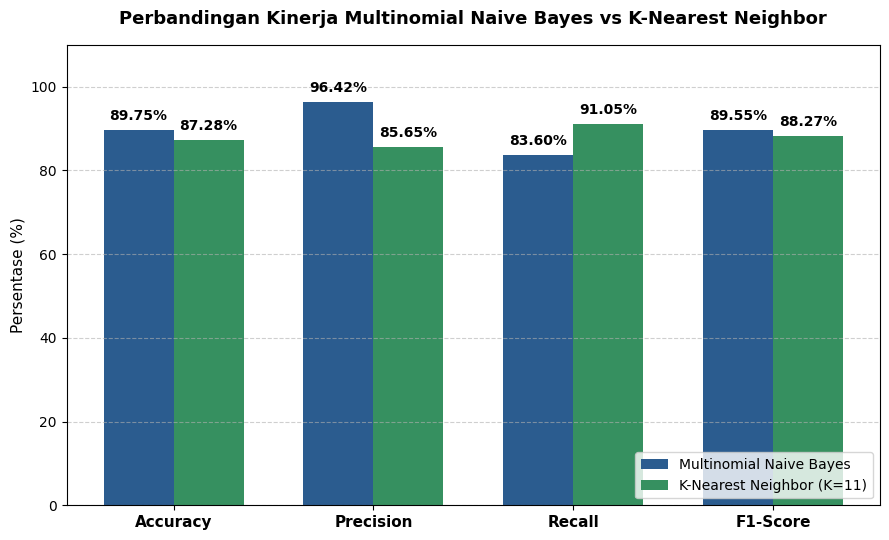

-> Grafik berhasil disimpan ke: ../data/hasil-perbandingan/grafik_perbandingan_mnb_vs_knn.png


In [4]:
# Daftar nama metrik dan nilainya untuk masing-masing metode
nama_metrik = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
nilai_mnb = [acc_mnb_pct, prec_mnb_pct, rec_mnb_pct, f1_mnb_pct]
nilai_knn = [acc_knn_pct, prec_knn_pct, rec_knn_pct, f1_knn_pct]

x = np.arange(len(nama_metrik))
lebar_batang = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))
batang_mnb = ax.bar(x - lebar_batang/2, nilai_mnb, lebar_batang, label='Multinomial Naive Bayes', color='#2b5c8f')
batang_knn = ax.bar(x + lebar_batang/2, nilai_knn, lebar_batang, label=f'K-Nearest Neighbor (K={k_terbaik})', color='#369060')

ax.set_title('Perbandingan Kinerja Multinomial Naive Bayes vs K-Nearest Neighbor', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Persentase (%)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(nama_metrik, fontsize=11, fontweight='bold')
ax.set_ylim(0, 110)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(fontsize=10, loc='lower right')

# Fungsi untuk menampilkan angka persentase di atas setiap batang
for batang in [batang_mnb, batang_knn]:
    for rect in batang:
        tinggi = rect.get_height()
        ax.annotate(
            f'{tinggi:.2f}%',
            xy=(rect.get_x() + rect.get_width() / 2, tinggi),
            xytext=(0, 5),
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=10, fontweight='bold'
        )

plt.tight_layout()
plt.savefig(f"{folder_perbandingan}/grafik_perbandingan_mnb_vs_knn.png", dpi=300)
plt.show()
print(f"-> Grafik berhasil disimpan ke: {folder_perbandingan}/grafik_perbandingan_mnb_vs_knn.png")

---
## 5. Perbandingan *Side-by-Side Confusion Matrix* & Analisis Pola Kesalahan

**Sesuai Subbab 3.12.6 & 3.13 Proposal Skripsi:**
Selain melihat angka persentase, kita membandingkan **Confusion Matrix** kedua metode secara berdampingan untuk memahami **pola kesalahan klasifikasi** masing-masing algoritma:

1. **Karakteristik Multinomial Naive Bayes:**
   - Memiliki nilai **True Negative (TN = 984)** yang sangat tinggi dan **False Positive (FP = 35)** yang sangat rendah.
   - Artinya: MNB **sangat akurat dalam mengenali keluhan/ulasan negatif** (96,57% ulasan negatif berhasil dikenali dengan tepat), sehingga sangat jarang salah menganggap ulasan negatif sebagai positif (**Precision = 96,42%**).
   - Kelemahannya terletak pada **False Negative (FN = 185)**, yaitu ketika pengguna memberikan rating bintang 4–5 (label aktual Positif) namun di dalam teks ulasannya menyertakan kata keluhan/kritik (misal: *"aplikasi bagus tapi kadang agak lambat"*), MNB cenderung memprediksinya sebagai Negatif.

2. **Karakteristik K-Nearest Neighbor ($K = 11$):**
   - Memiliki nilai **True Positive (TP = 1027)** dan **Recall (91,05%)** yang lebih tinggi dibanding Naive Bayes.
   - Namun, KNN memiliki **False Positive (FP = 172)** yang jauh lebih besar dibanding Naive Bayes (35).
   - Artinya: Pada metode KNN, banyak ulasan yang sebenarnya **Negatif** justru salah ditebak sebagai **Positif** karena kemiripan kata umum (*Cosine Similarity*) dengan tetangga kelas Positif yang jumlahnya lebih dominan di Data Latih.

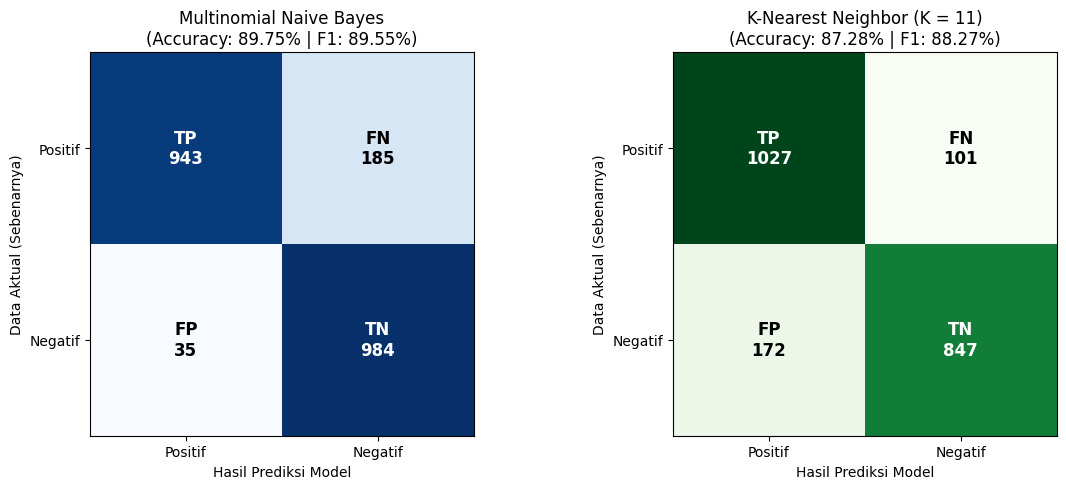

-> Gambar Confusion Matrix berdampingan disimpan ke: ../data/hasil-perbandingan/confusion_matrix_side_by_side.png


In [5]:
# Menampilkan 2 Confusion Matrix secara berdampingan (Side-by-Side)
cm_mnb = eval_mnb['confusion_matrix']
cm_knn = eval_knn['confusion_matrix']
label_kotak = [['TP', 'FN'], ['FP', 'TN']]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Multinomial Naive Bayes
im1 = axes[0].imshow(cm_mnb, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=['Positif', 'Negatif'], yticklabels=['Positif', 'Negatif'],
    title=f'Multinomial Naive Bayes\n(Accuracy: {acc_mnb_pct}% | F1: {f1_mnb_pct}%)',
    ylabel='Data Aktual (Sebenarnya)', xlabel='Hasil Prediksi Model'
)
thresh1 = cm_mnb.max() / 2.0
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{label_kotak[i][j]}\n{cm_mnb[i, j]}", ha="center", va="center",
                     color="white" if cm_mnb[i, j] > thresh1 else "black", fontsize=12, fontweight='bold')

# Plot 2: K-Nearest Neighbor (K Terbaik)
im2 = axes[1].imshow(cm_knn, interpolation='nearest', cmap=plt.cm.Greens)
axes[1].set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=['Positif', 'Negatif'], yticklabels=['Positif', 'Negatif'],
    title=f'K-Nearest Neighbor (K = {k_terbaik})\n(Accuracy: {acc_knn_pct}% | F1: {f1_knn_pct}%)',
    ylabel='Data Aktual (Sebenarnya)', xlabel='Hasil Prediksi Model'
)
thresh2 = cm_knn.max() / 2.0
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{label_kotak[i][j]}\n{cm_knn[i, j]}", ha="center", va="center",
                     color="white" if cm_knn[i, j] > thresh2 else "black", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{folder_perbandingan}/confusion_matrix_side_by_side.png", dpi=300)
plt.show()
print(f"-> Gambar Confusion Matrix berdampingan disimpan ke: {folder_perbandingan}/confusion_matrix_side_by_side.png")

### Bedah Kasus Prediksi Berbeda Antara MNB dan KNN pada Data Uji
Tabel di bawah ini menampilkan contoh ulasan pada Data Uji di mana **Multinomial Naive Bayes memprediksi dengan BENAR, sedangkan KNN memprediksi SALAH**.

In [6]:
df_komparasi_prediksi = pd.DataFrame({
    'Teks_Ulasan_Bersih': X_test_text.values,
    'Label_Aktual': y_test.values,
    'Prediksi_MNB': eval_mnb['y_pred'],
    f'Prediksi_KNN_K{k_terbaik}': eval_knn['y_pred']
})

mnb_benar = df_komparasi_prediksi['Prediksi_MNB'] == df_komparasi_prediksi['Label_Aktual']
knn_benar = df_komparasi_prediksi[f'Prediksi_KNN_K{k_terbaik}'] == df_komparasi_prediksi['Label_Aktual']

sama_sama_benar = (mnb_benar & knn_benar).sum()
mnb_benar_knn_salah = (mnb_benar & ~knn_benar).sum()
knn_benar_mnb_salah = (~mnb_benar & knn_benar).sum()
sama_sama_salah = (~mnb_benar & ~knn_benar).sum()

print("=== RINGKASAN KESESUAIAN PREDIKSI PADA 2.147 DATA UJI ===")
print(f"1. Kedua Metode Sama-Sama Benar        : {sama_sama_benar} ulasan")
print(f"2. MNB Benar, tetapi KNN Salah         : {mnb_benar_knn_salah} ulasan")
print(f"3. KNN Benar, tetapi MNB Salah         : {knn_benar_mnb_salah} ulasan")
print(f"4. Kedua Metode Sama-Sama Salah        : {sama_sama_salah} ulasan")

print("\nContoh 5 Ulasan di mana Multinomial Naive Bayes BENAR sedangkan KNN SALAH:")
display(df_komparasi_prediksi[mnb_benar & ~knn_benar].head(5))

=== RINGKASAN KESESUAIAN PREDIKSI PADA 2.147 DATA UJI ===
1. Kedua Metode Sama-Sama Benar        : 1785 ulasan
2. MNB Benar, tetapi KNN Salah         : 142 ulasan
3. KNN Benar, tetapi MNB Salah         : 89 ulasan
4. Kedua Metode Sama-Sama Salah        : 131 ulasan

Contoh 5 Ulasan di mana Multinomial Naive Bayes BENAR sedangkan KNN SALAH:


,Teks_Ulasan_Bersih,Label_Aktual,Prediksi_MNB,Prediksi_KNN_K11
4,minta kemudi suka lama,negatif,negatif,positif
7,aplikasi sangat tidak guna aplikasi sangat ker...,negatif,negatif,positif
16,awal naik ojek motor murah hemat beli pulsa to...,negatif,negatif,positif
19,sama hancur reting gojek aplikasi gogle play g...,negatif,negatif,positif
53,kemudi tidak sopan,negatif,negatif,positif


---
## 6. Pengujian Hipotesis Penelitian ($H_0$ vs $H_1$) & Kesimpulan Akhir

**Sesuai Subbab 2.4 (Hipotesis Penelitian) pada Proposal Skripsi:**
- **$H_0$ (Hipotesis Nol):** Tidak terdapat perbedaan kinerja yang signifikan antara metode Multinomial Naive Bayes dan K-Nearest Neighbor dalam melakukan analisis sentimen ulasan pengguna Gojek di Google Play Store berdasarkan nilai *accuracy, precision, recall,* dan *F1-score*.
- **$H_1$ (Hipotesis Alternatif):** Terdapat perbedaan kinerja yang signifikan antara metode Multinomial Naive Bayes dan K-Nearest Neighbor dalam melakukan analisis sentimen ulasan pengguna Gojek di Google Play Store berdasarkan nilai *accuracy, precision, recall,* dan *F1-score*.

### Catatan Belajar: Uji Statistik McNemar (*McNemar's Test*)
Untuk membuktikan secara ilmiah apakah perbedaan kinerja kedua algoritma pada Data Uji yang sama signifikan secara statistik (taraf signifikansi $\alpha = 0.05$), kita menggunakan **Uji McNemar**:
$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$$
- $b$ = Jumlah data uji di mana **MNB Benar & KNN Salah**
- $c$ = Jumlah data uji di mana **KNN Benar & MNB Salah**
- Jika nilai **$p\text{-value} < 0.05$**, maka **$H_0$ ditolak dan $H_1$ diterima** (terdapat perbedaan kinerja yang signifikan).

In [7]:
# Perhitungan Uji McNemar untuk menguji Hipotesis H0 vs H1
b = mnb_benar_knn_salah
c = knn_benar_mnb_salah

chi2_stat = ((abs(b - c) - 1) ** 2) / (b + c)
p_value = 1 - chi2.cdf(chi2_stat, df=1)

print("=" * 68)
print("   HASIL PENGUJIAN HIPOTESIS & KESIMPULAN AKHIR PENELITIAN")
print("=" * 68)
print(f"1. Statistik Uji McNemar (Chi-Square) : {chi2_stat:.4f}")
print(f"2. Nilai p-value                      : {p_value:.6f}")
if p_value < 0.05:
    print("3. Keputusan Hipotesis                : H0 DITOLAK dan H1 DITERIMA (p-value < 0.05)")
    print("   -> Terdapat perbedaan kinerja yang signifikan antara Multinomial Naive Bayes dan KNN.")
else:
    print("3. Keputusan Hipotesis                : H0 DITERIMA (p-value >= 0.05)")

print("-" * 68)
print("KESIMPULAN METODE TERBAIK:")
print(f"Berdasarkan eksperimen pada dataset ulasan aplikasi Gojek ({len(y_test)} data uji):")
print(f"- Multinomial Naive Bayes memperoleh Accuracy {acc_mnb_pct}%, Precision {prec_mnb_pct}%, Recall {rec_mnb_pct}%, dan F1-Score {f1_mnb_pct}%.")
print(f"- K-Nearest Neighbor terbaik (K={k_terbaik}) memperoleh Accuracy {acc_knn_pct}%, Precision {prec_knn_pct}%, Recall {rec_knn_pct}%, dan F1-Score {f1_knn_pct}%.")
print(f"\n=> Metode MULTINOMIAL NAIVE BAYES terbukti memiliki kinerja yang LEBIH UNGGUL dibandingkan")
print(f"   K-Nearest Neighbor dengan selisih keunggulan Accuracy sebesar +{acc_mnb_pct - acc_knn_pct:.2f}% dan F1-Score sebesar +{f1_mnb_pct - f1_knn_pct:.2f}%.")
print("=" * 68)

   HASIL PENGUJIAN HIPOTESIS & KESIMPULAN AKHIR PENELITIAN
1. Statistik Uji McNemar (Chi-Square) : 11.7056
2. Nilai p-value                      : 0.000623
3. Keputusan Hipotesis                : H0 DITOLAK dan H1 DITERIMA (p-value < 0.05)
   -> Terdapat perbedaan kinerja yang signifikan antara Multinomial Naive Bayes dan KNN.
--------------------------------------------------------------------
KESIMPULAN METODE TERBAIK:
Berdasarkan eksperimen pada dataset ulasan aplikasi Gojek (2147 data uji):
- Multinomial Naive Bayes memperoleh Accuracy 89.75%, Precision 96.42%, Recall 83.6%, dan F1-Score 89.55%.
- K-Nearest Neighbor terbaik (K=11) memperoleh Accuracy 87.28%, Precision 85.65%, Recall 91.05%, dan F1-Score 88.27%.

=> Metode MULTINOMIAL NAIVE BAYES terbukti memiliki kinerja yang LEBIH UNGGUL dibandingkan
   K-Nearest Neighbor dengan selisih keunggulan Accuracy sebesar +2.47% dan F1-Score sebesar +1.28%.
